In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# Load the dataset
df = pd.read_csv('D1.csv')

contagem = df['FTR'].value_counts().to_string()
print(f"{contagem}")
df['FTR'] = df['FTR'].astype('string')
df['MaxH'] = df['MaxH'].astype('float')
df['MaxA'] = df['MaxA'].astype('float')
df['MaxD'] = df['MaxD'].astype('float')

hw = ((df['MaxH'] < df['MaxA']) & (df['FTR'] == 'H')).sum()
print(f"Odd acertada casa: {hw}")

aw = ((df['MaxA'] < df['MaxH']) & (df['FTR'] == 'A')).sum()
print(f"Odd acertada visitante: {aw}")

dw = ((df['MaxD'] < df['MaxH']) & (df['MaxD'] < df['MaxA']) & (df['FTR'] == 'D')).sum()
print(f"Odd acertada empate: {dw}")

odd_errou = ((df['MaxH'] < df['MaxA']) & (df['FTR'] == 'A')).sum() + ((df['MaxA'] < df['MaxH']) & (df['FTR'] == 'H')).sum() + ((df['MaxD'] < df['MaxH']) & (df['MaxD'] < df['MaxA']) & (df['FTR'] != 'D')).sum() + ((df['MaxA'] < df['MaxH']) & (df['FTR'] == 'D')).sum() + ((df['MaxH'] < df['MaxA']) & (df['FTR'] == 'D')).sum()
print(f"Odd erradas: {odd_errou}")



total = len(df)
print(f"Total de jogos: {total}")

hw_percent = (hw / total) * 100
aw_percent = (aw / total) * 100
dw_percent = (dw / total) * 100
erro_percent = (odd_errou / total) * 100
print(f"Odd acertada casa: {hw_percent:.2f}%")
print(f"Odd acertada visitante: {aw_percent:.2f}%")
print(f"Odd acertada empate: {dw_percent:.2f}%")

FTR
H    134
A     91
D     81
Odd acertada casa: 110
Odd acertada visitante: 54
Odd acertada empate: 0
Odd erradas: 142
Total de jogos: 306
Odd acertada casa: 35.95%
Odd acertada visitante: 17.65%
Odd acertada empate: 0.00%


Text(0.5, 1.0, 'Porcentagem de Acertos das Odds(Bundesliga)')

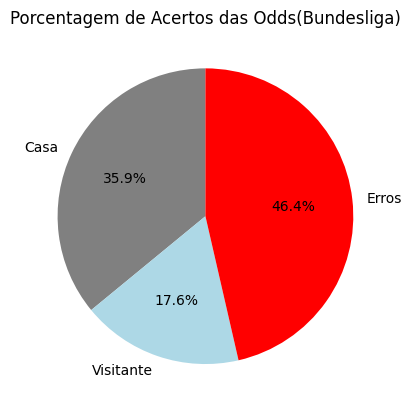

In [12]:
pizza = [hw_percent, aw_percent, erro_percent]
labels = ['Casa', 'Visitante', 'Erros']
plt.pie(pizza, labels=labels, autopct='%1.1f%%', startangle=90, colors=['gray', 'lightblue', 'red'])
plt.title('Porcentagem de Acertos das Odds(Bundesliga)')

Text(0.5, 23.52222222222222, 'Visitante')

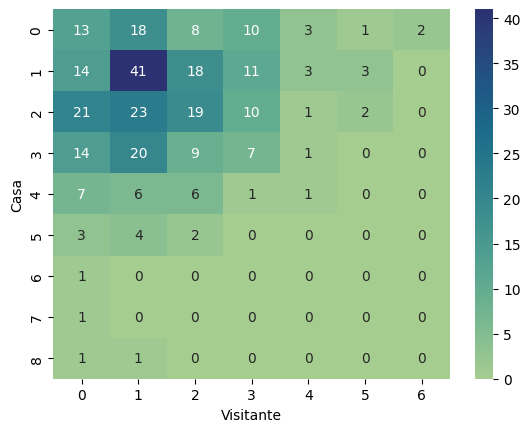

In [11]:
df['FTAG'] = df['FTAG'].astype('int')
golsa = df['FTAG'].value_counts()
golsh = df['FTHG'].value_counts()

frequencia = pd.crosstab(df['FTHG'], df['FTAG'])

sns.heatmap(frequencia, annot=True, fmt='d', cmap="crest")
plt.ylabel('Casa')
plt.xlabel('Visitante')
##print(golsa)
##print(golsh)